# Dynamic player availability

Stage 03 estimates quality. Stage 04 tracks **record-based pre-event availability** and nominal bowling capacity. Stage 05 combines them into resource features. No models, splits, probabilities or NWC here.

`RUN_STAGE = True` explicitly rebuilds. `False` verifies and reads existing results, without automatic rebuilding. `SAVE_FIGURES` only refreshes presentation files.


In [9]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'config/player_availability.json').is_file()
             and (p / 'src/player_availability.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import player_availability as stage
import player_availability_visualisation as viz
from audit_visualisation import table
importlib.reload(stage)
importlib.reload(viz)
RUN_STAGE = False
SAVE_FIGURES = True
OUTPUT = ROOT / stage.REPORT_DIR
DATA = ROOT / stage.DATA_DIR
print('Project:', ROOT)
print('Python:', sys.executable)


Project: D:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe


## 1. Build or verify

Inputs: source JSON, Stage 01 cleaned order and Stage 03 identity catalogue. A listed participant is not automatically an initial or active player. Initial XIs are reconstructed by removing explicitly recorded incoming replacements, not by looking at future appearances.


In [10]:
if RUN_STAGE:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
print('Verified availability export:', summary['availability_id'])
print('Upstream quality export:', summary['upstream_quality_id'])
display(table(pd.DataFrame([{'Check': k, 'Passed': v} for k, v in summary['checks'].items()]), 'Integrity checks'))


Verified availability export: e87e817800131e0c54c1e37c3baae23579ad457f1ced6d5daaace6f9292275f3
Upstream quality export: f5ca00d19816ce50dbfea8ad23962809760ae1622322726dcc0d55ae5731e832


Check,Passed
all_source_events_accounted_for,True
replayed_source_order_unchanged,True
current_pair_partition,True
nonnegative_bounded_nominal_capacity,True
whole_match_resource_gate,True
stage03_cohort_unchanged,True


## 2. Coverage and the resource-readiness gate

Ready means no flagged special-case restriction in this record-based reconstruction, not certified medical/legal eligibility. Review means retirement, replacement or untimed absence needs a defensible resource policy. Quarantined means replay could not explain a source/state conflict.

All replayed rows remain diagnostic. Only explicit ready **whole matches** may pass `load_resource_events` into a formal resource experiment. All comparison arms must use the same cohort and date split. This notebook does not select a final training cohort or resolve reviews by deleting matches.


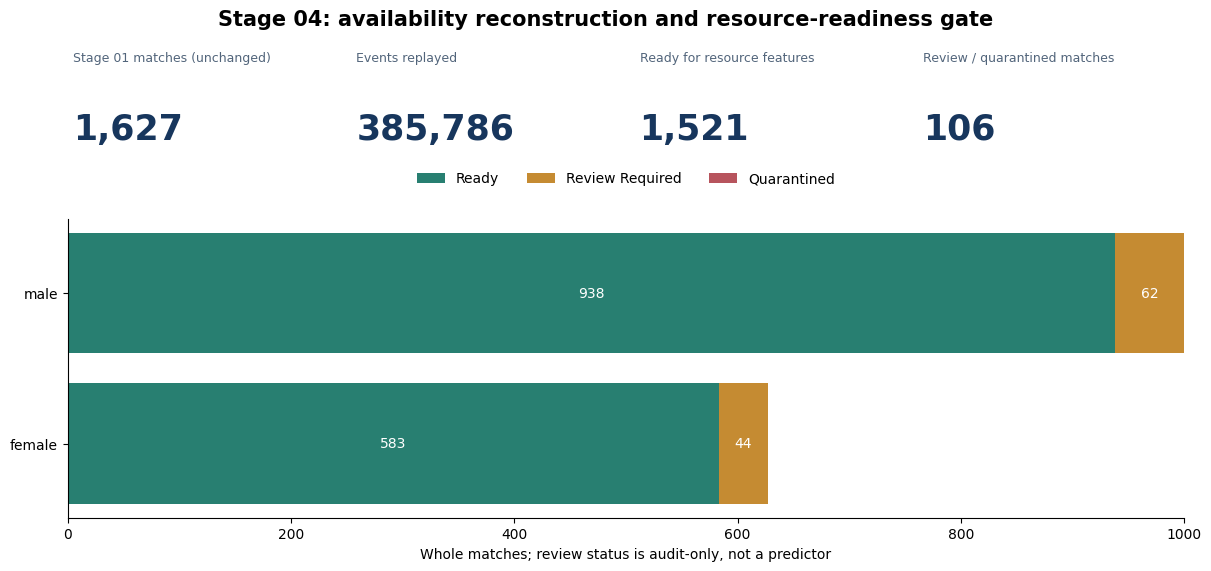

gender,status,matches,events
female,ready,583,137309
female,review_required,44,10413
male,ready,938,223412
male,review_required,62,14652


Upstream matches retained: 1627
Ready matches / events: 1521 / 360721
Review-required matches: 106
Quarantined matches: 0


In [11]:
coverage = pd.read_csv(OUTPUT / 'coverage.csv')
audit = pd.read_csv(OUTPUT / 'match_availability_audit.csv')
issues = pd.read_csv(OUTPUT / 'review_issues.csv')
figures = viz.build_figures(ROOT, summary)
display(figures['availability_coverage.png'])
display(table(coverage, 'Coverage by gender and resource-review status'))
print('Upstream matches retained:', summary['matches'])
print('Ready matches / events:', summary['ready_matches'], '/', summary['ready_events'])
print('Review-required matches:', summary['review_matches'])
print('Quarantined matches:', summary['quarantined_matches'])


## 3. Who can still bat?

The current pair is included in available players and excluded from waiting players. A dismissal affects the next event, not the pre-event state of its own delivery. Temporary retirement is not a wicket. Return is recognised from a current actor, not a future appearance. Stage 05 uses only waiting_not_yet_batted with previously_observed_batting=0; waiting_returned is excluded from its resource pool. A new non-striker is already a current_batter and is excluded before facing a ball.

The special-case example is diagnostic and may require review. Untimed `absent_hurt` does not remove a player from earlier states; inferred and actual counts may differ. The separate audit flags that limitation.


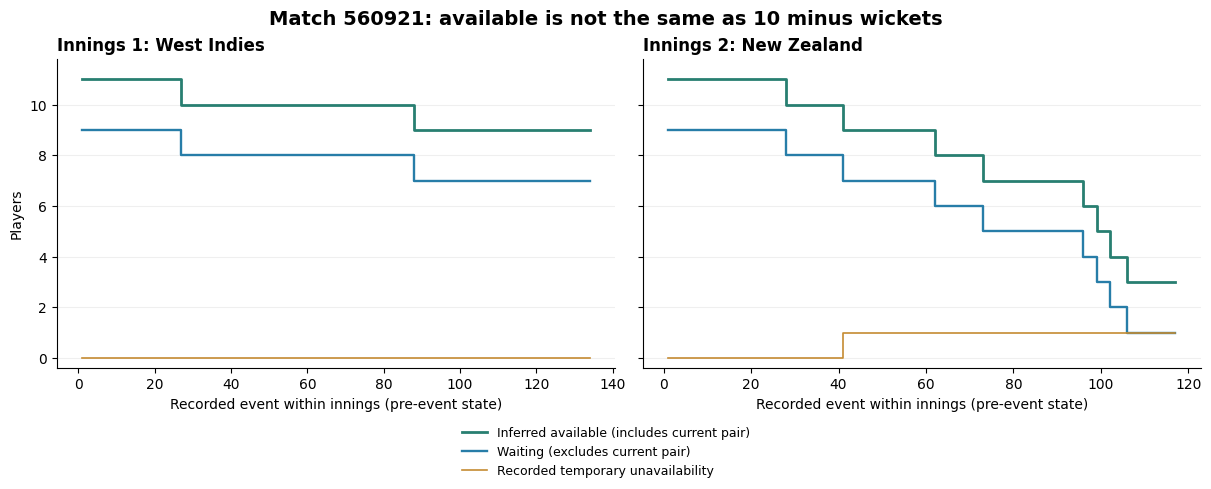

Diagnostic example: 560921


match_innings,event_sequence,available_batter_count,waiting_batter_count,temporarily_unavailable_batter_count,dismissed_slot_count
1,1,11,9,0,0
1,2,11,9,0,0
1,3,11,9,0,0
1,4,11,9,0,0
1,5,11,9,0,0
1,6,11,9,0,0
1,7,11,9,0,0
1,8,11,9,0,0
1,9,11,9,0,0
1,10,11,9,0,0


In [12]:
display(figures['batting_availability.png'])
example_label = 'retirement' if 'retirement' in summary['example_matches'] else 'ordinary'
example = pd.read_csv(OUTPUT / f'example_{example_label}.csv.gz')
print('Diagnostic example:', summary['example_matches'][example_label])
display(table(example[['match_innings', 'event_sequence', 'available_batter_count', 'waiting_batter_count',
                       'temporarily_unavailable_batter_count', 'dismissed_slot_count']].head(12), 'First twelve pre-event states'))


## 4. What bowling capacity remains?

Track personal legal balls and over slots separately. Wides/no-balls do not consume legal balls. An interrupted over counts towards each participating bowler's allowance. A continuation past six legal balls does not reveal future over length.

These are **individual nominal upper bounds**, not actual allocations or legal next-bowler choices. Stage 05 sums each remaining capacity / 6 times bowling quality, including the current bowler, without allocating the innings budget. Total capacity may exceed the innings budget and must not be labelled remaining innings balls. Shared replacement-slot inheritance is a diagnostic approximation requiring review.


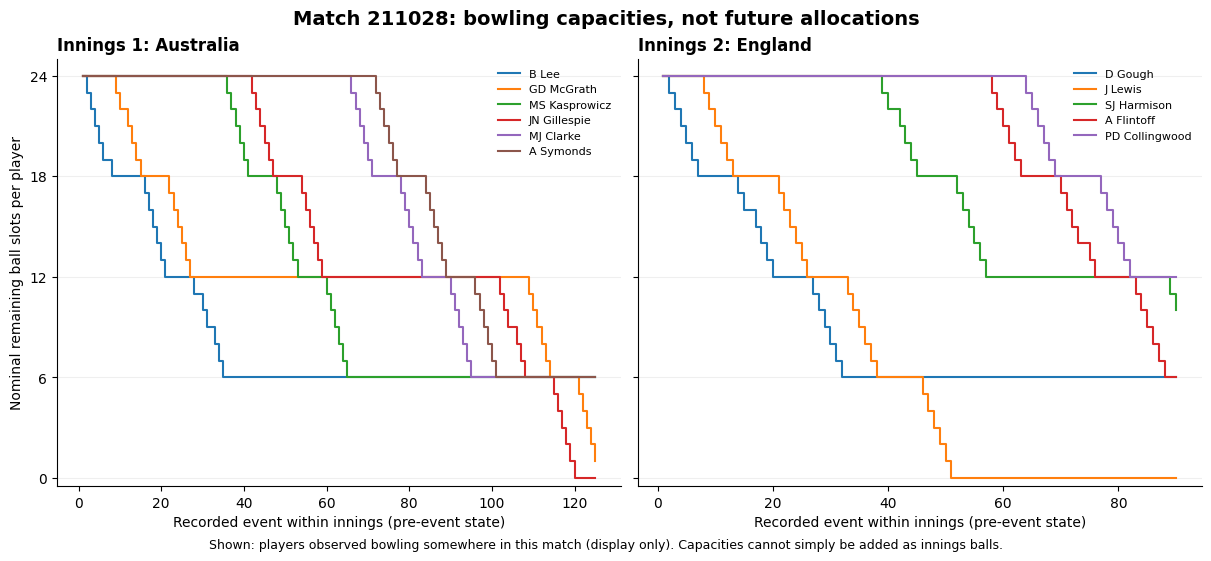

In [13]:
display(figures['bowling_capacity.png'])


## 5. When did the state change?

Replacement records apply before the delivery. Wicket/retirement consequences apply after it. Timeline coordinate event number + 0.5 means after-event consequence, not another delivery.


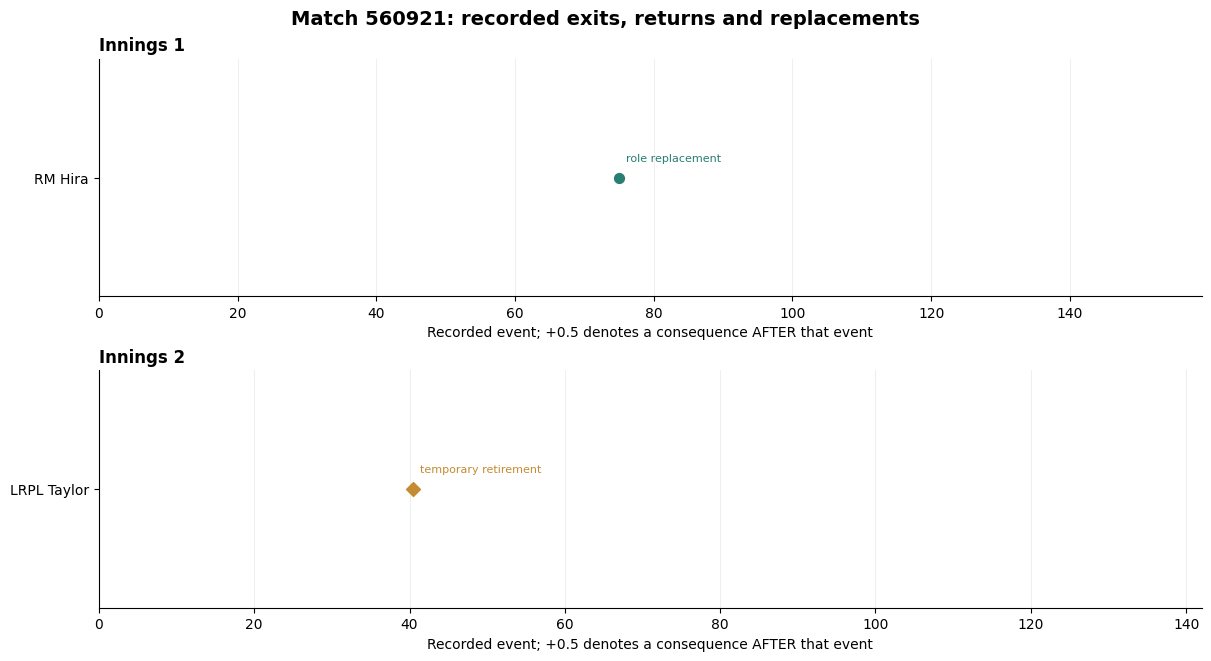

source_row,match_id,match_innings,event_sequence,timing,event,player_id,detail
1184072,560921,1,26,after,dismissal,35205dfc,bowled
1184121,560921,1,75,before,role_replacement,2e966563,"{""in"":""KS Williamson"",""reason"":""injury"",""role"":""bowler""}"
1184133,560921,1,87,after,dismissal,09a9d073,caught
1184207,560921,2,27,after,dismissal,2be41edb,stumped
1184220,560921,2,40,after,temporary_retirement,b61a3e1a,retired hurt
1184241,560921,2,61,after,dismissal,d027ba9f,caught and bowled
1184252,560921,2,72,after,dismissal,8d8c24fd,caught
1184275,560921,2,95,after,dismissal,13c35c9e,stumped
1184278,560921,2,98,after,dismissal,e824e6ee,run out
1184281,560921,2,101,after,dismissal,22bd731a,run out


In [14]:
display(figures['availability_timeline.png'])
transitions = pd.read_csv(DATA / 'availability_transitions.csv.gz')
local_transitions = transitions.loc[transitions.match_id.eq(int(example.match_id.iloc[0]))]
display(table(local_transitions, 'Source-linked example transitions', collapsed=True))


## 6. Review before constructing resources

Reason counts overlap: do not add them as unique matches. They describe reconstruction limitations, **not source-data corruption classifications**. The resource-eligibility policy holds retirement, role/match replacement and untimed absence for review. Better evidence or an explicitly labelled sensitivity analysis may recover some cases; do not silently release them.

Retrospective review flags, outcomes, player IDs and future availability are not predictors. Unrecorded injury and fielding absence remain a limitation even in ready matches.


In [15]:
reasons = pd.read_csv(OUTPUT / 'review_reason_counts.csv')
display(table(reasons, 'Review reasons (overlapping)'))
display(table(audit.loc[~audit.ready_for_resource_features], 'Matches requiring review', collapsed=True))
display(table(issues, 'Complete review evidence', collapsed=True))


reason,blocks_resources,matches,records
bowling_return_penalty_time_unverified,True,2,2
match_replacement_restrictions_unverified,True,11,11
observed_over_continuation,False,8,9
retirement_return_conditions_unverified,True,26,26
role_replacement_restrictions_unverified,True,61,62
untimed_absent_hurt,True,17,17


match_id,gender,match_date,source_events,replayed_events,status,ready_for_resource_features,reasons
222678,male,2005-10-21,233,233,review_required,False,match_replacement_restrictions_unverified
251488,male,2006-12-26,230,230,review_required,False,role_replacement_restrictions_unverified
255954,male,2006-12-01,248,248,review_required,False,role_replacement_restrictions_unverified
287874,male,2007-09-20,185,185,review_required,False,role_replacement_restrictions_unverified
287875,male,2007-09-20,246,246,review_required,False,role_replacement_restrictions_unverified
343764,male,2008-04-20,228,228,review_required,False,role_replacement_restrictions_unverified
426723,male,2009-11-12,235,235,review_required,False,role_replacement_restrictions_unverified | untimed_absent_hurt
518954,male,2012-02-01,248,248,review_required,False,bowling_return_penalty_time_unverified | role_replacement_restrictions_unverified
533301,female,2012-09-27,246,246,review_required,False,role_replacement_restrictions_unverified
560921,male,2012-06-30,251,251,review_required,False,retirement_return_conditions_unverified | role_replacement_restrictions_unverified | untimed_absent_hurt


match_id,match_innings,source_row,reason,detail,blocks_resources
222678,2,1.121761e+06,match_replacement_restrictions_unverified,"{""in"":""JAH Marshall"",""out"":""JS Patel"",""reason"":""supersub"",""team"":""New Zealand""}",True
251488,1,1.123594e+06,role_replacement_restrictions_unverified,"{""in"":""NJ Astle"",""reason"":""injury"",""role"":""bowler""}",True
255954,1,1.123801e+06,role_replacement_restrictions_unverified,"{""in"":""SR Tendulkar"",""reason"":""injury"",""role"":""bowler""}",True
287871,2,1.128712e+06,observed_over_continuation,Nominal current-over slots exhausted,False
287874,1,1.129347e+06,role_replacement_restrictions_unverified,"{""in"":""A Symonds"",""reason"":""injury"",""role"":""bowler""}",True
287875,2,1.129550e+06,role_replacement_restrictions_unverified,"{""in"":""Mohammad Hafeez"",""out"":""Imran Nazir"",""reason"":""injury"",""role"":""batter""}",True
343764,1,1.133603e+06,role_replacement_restrictions_unverified,"{""in"":""Mahmudullah"",""reason"":""injury"",""role"":""bowler""}",True
412702,1,1.152425e+06,observed_over_continuation,Nominal current-over slots exhausted,False
412702,2,1.152529e+06,observed_over_continuation,Nominal current-over slots exhausted,False
426723,1,1.155531e+06,role_replacement_restrictions_unverified,"{""in"":""NL McCullum"",""reason"":""injury"",""role"":""bowler""}",True


## 7. Handoff to Stage 05

One row per replayed source event is saved in `event_availability.csv.gz`. Its batting/bowling JSON arrays hold per-player states. Join quality by match, gender and player ID. Future incoming replacements do not appear in earlier snapshots.

Use `stage.load_resource_events(ROOT, explicit_ready_match_ids)` for formal resources. Empty, unknown or review-required requests are rejected rather than silently filtered. No quality weighting occurs here.


In [16]:
contract = json.loads((OUTPUT / 'feature_contract.json').read_text(encoding='utf-8'))
display(table(pd.DataFrame([{'State': 'Batting', 'Array fields': ', '.join(contract['batting_state_schema'])},
                            {'State': 'Bowling', 'Array fields': ', '.join(contract['bowling_state_schema'])}]), 'Player-state array schemas'))
if SAVE_FIGURES:
    print('Saved figures:', viz.save_figures(ROOT, summary, figures))
for figure in figures.values():
    plt.close(figure)
print('Models trained:', summary['models_trained'])
print('Processed data:', DATA)
print('Reports:', OUTPUT)
print('Next stage: 05_remaining_resource_features.ipynb')


State,Array fields
Batting,"player_id, resource_slot_id, status, previously_observed_batting"
Bowling,"player_id, resource_slot_id, status, personal_legal_balls, slot_legal_balls, slot_overs_started, nominal_capacity"


Saved figures: D:\T20_Project\T20_Project_3.0\outputs\04_dynamic_player_availability\figures
Models trained: 0
Processed data: D:\T20_Project\T20_Project_3.0\data\processed\player_availability
Reports: D:\T20_Project\T20_Project_3.0\outputs\04_dynamic_player_availability
Next stage: 05_remaining_resource_features.ipynb
